# 04 — Inverse neural net (lab results, not re-run)

Supervised mapping from generation + calendar features to `(pv_dc_kwp, tilt, orientation)`.

**How to read these numbers.** Training used a random 80/20 *row* split of synthetic 30-minute samples, not a site-level or temporal holdout. The reported MAE is small while MAPE on capacity is ~90%, which is consistent with a denormalisation / target-column bug. Treat the metrics as a snapshot of the lab notebook, not as a claim that the inverse problem is solved.

Weights: `models/best_model.pth`. Training data: 100 synthetic CSVs in `data/synthetic/generated/` (gitignored; regenerate with `python src/generate_synthetic.py --n-sites 100`). Real-site validation CSV is optional and proprietary.


# Simple Neural Network Program
### This JupyterNotebook will generate Build a simple NN which can predict the location and panel data reversely to the pvlib.​ It shall be a self-contained pipeline which all group member can easily applied for their own training.​

#### Question to answer before building the model 

- What are the inputs ? Is it a time serie with energy produced ? (if so how long is the time serie ? )

- What is the output ? A region like a country or an area (i.e. is it a classification pb ?), is it latitude and longitude ? (i.e. regression pb ?)

ans: 
Our goal is to build a model that acts as an inverse of the pvlib analytical model. We'll use the pvlib method to generate synthetic data for training.

The inputs will be: date, power generated at 30-minute intervals over a full year, panel tilt angle, panel orientation, and panel capacity. The outputs will be the longitude and latitude.

This will be a regression model, with the output longitude and latitude verified against real data.
(Yifei 3.Feb)


In [8]:
## Author:
## Date:
## Description:
## Change History:
## Libraries and versions:

## Initialization

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path('..') / 'src'))
from simple_nn import SimpleNN
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch


## Data pre-process

In [2]:
# Merge synthetic sites. Full 100-site panel lives in generated/ (gitignored).
import os
from pathlib import Path

generated = Path('../data/synthetic/generated')
sample = Path('../data/synthetic/sample_site_0.csv')
if generated.exists() and any(generated.glob('*.csv')):
    data_folder = str(generated)
    csv_files = [f for f in os.listdir(data_folder) if f.endswith('.csv')]
    data_list = [pd.read_csv(os.path.join(data_folder, file)) for file in csv_files]
    merged_data = pd.concat(data_list, ignore_index=True)
    print(f'Loaded {len(csv_files)} generated site files')
else:
    merged_data = pd.read_csv(sample)
    print('generated/ is empty — loaded public sample_site_0.csv only')
## Original 17-feature tables contained data leakage. Need to change


In [3]:

# Display the first few rows of the merged dataframe
print(merged_data)
# Show basic statistical information of the merged dataframe
# print(merged_data.describe())
# Check for missing values in the merged dataframe
# print("Number of missing values in each column:")
# print(merged_data.isna().sum())




                     timestamp_utc  site_id  latitude  longitude  pv_dc_kwp  \
0        2022-11-17 00:00:00+00:00       43   46.8660     7.4605       4.47   
1        2022-11-17 00:30:00+00:00       43   46.8660     7.4605       4.47   
2        2022-11-17 01:00:00+00:00       43   46.8660     7.4605       4.47   
3        2022-11-17 01:30:00+00:00       43   46.8660     7.4605       4.47   
4        2022-11-17 02:00:00+00:00       43   46.8660     7.4605       4.47   
...                            ...      ...       ...        ...        ...   
1751995  2023-09-16 21:30:00+00:00       66   56.8012    -5.7326       1.40   
1751996  2023-09-16 22:00:00+00:00       66   56.8012    -5.7326       1.40   
1751997  2023-09-16 22:30:00+00:00       66   56.8012    -5.7326       1.40   
1751998  2023-09-16 23:00:00+00:00       66   56.8012    -5.7326       1.40   
1751999  2023-09-16 23:30:00+00:00       66   56.8012    -5.7326       1.40   

         pv_array_tilt  pv_array_a_orientation  sol

In [4]:
from sklearn.preprocessing import StandardScaler ## library for normalization datainput


## X will be the input training data and y will be output training data
X = merged_data.copy()
# Convert timestamp_utc to datetime
X['timestamp_utc'] = pd.to_datetime(X['timestamp_utc'])

# Extract useful features from timestamp_utc
X['year'] = X['timestamp_utc'].dt.year
X['month'] = X['timestamp_utc'].dt.month
X['day'] = X['timestamp_utc'].dt.day
X['hour'] = X['timestamp_utc'].dt.hour
X['minute'] = X['timestamp_utc'].dt.minute

# Convert month and hour to cyclic features
X['month_sin'] = np.sin(2 * np.pi * X['month'] / 12)
X['month_cos'] = np.cos(2 * np.pi * X['month'] / 12)
X['hour_sin'] = np.sin(2 * np.pi * X['hour'] / 24)
X['hour_cos'] = np.cos(2 * np.pi * X['hour'] / 24)

# Drop the original month and hour columns
X = X.drop(['month', 'hour'], axis=1)

# Drop the original timestamp_utc column and other info leakage columns
X = X.drop(columns=['timestamp_utc','site_id'])

# Normalise
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
print(X.head())

# Drop the target parameters
y = X[['pv_dc_kwp', 'pv_array_tilt', "pv_array_a_orientation"]]
X = X.drop(columns=y)
# printX and y
# print(y.head())

# Check for missing values in X
# print("Number of missing values in each column of X:")
# print(X.isna().sum())
# print(X)

   latitude  longitude  pv_dc_kwp  pv_array_tilt  pv_array_a_orientation  \
0 -0.639036  -0.404999   1.183061       1.166514                 1.15134   
1 -0.639036  -0.404999   1.183061       1.166514                 1.15134   
2 -0.639036  -0.404999   1.183061       1.166514                 1.15134   
3 -0.639036  -0.404999   1.183061       1.166514                 1.15134   
4 -0.639036  -0.404999   1.183061       1.166514                 1.15134   

   solar_gen_kwh     year       day  minute  month_sin  month_cos  \
0      -0.743971 -0.39713  0.144544    -1.0  -0.701627   1.225455   
1      -0.743971 -0.39713  0.144544     1.0  -0.701627   1.225455   
2      -0.743971 -0.39713  0.144544    -1.0  -0.701627   1.225455   
3      -0.743971 -0.39713  0.144544     1.0  -0.701627   1.225455   
4      -0.743971 -0.39713  0.144544    -1.0  -0.701627   1.225455   

       hour_sin  hour_cos  
0  1.960393e-17  1.414214  
1  1.960393e-17  1.414214  
2  3.660254e-01  1.366025  
3  3.660254e-01 

## Import 4 sites real data as final test data and normalised

In [5]:
# Define the path to the validation data file
validation_data_file = '../data/real/validation_Data.csv'  # proprietary; skip if missing

# Read the validation data
validation_data = pd.read_csv(validation_data_file)


# Extract useful features from timestamp_utc
validation_data['timestamp_utc'] = pd.to_datetime(validation_data['timestamp_utc'])
validation_data['year'] = validation_data['timestamp_utc'].dt.year
validation_data['month'] = validation_data['timestamp_utc'].dt.month
validation_data['day'] = validation_data['timestamp_utc'].dt.day
validation_data['hour'] = validation_data['timestamp_utc'].dt.hour
validation_data['minute'] = validation_data['timestamp_utc'].dt.minute
# Convert month and hour to cyclic features
validation_data['month_sin'] = np.sin(2 * np.pi * validation_data['month'] / 12)
validation_data['month_cos'] = np.cos(2 * np.pi * validation_data['month'] / 12)
validation_data['hour_sin'] = np.sin(2 * np.pi * validation_data['hour'] / 24)
validation_data['hour_cos'] = np.cos(2 * np.pi * validation_data['hour'] / 24)
# Drop the original month and hour columns
validation_data = validation_data.drop(['month', 'hour','timestamp_utc','site_id', 'apparent_zenith', 'azimuth'], axis=1)

validation_data = validation_data[['latitude', 'longitude', 'pv_dc_kwp', 'pv_array_tilt', 'pv_array_a_orientation', 'solar_gen_kwh', 'year', 'day', 'minute', 'month_sin', 'month_cos', 'hour_sin', 'hour_cos']]


# # 使用训练集的scaler进行归一化
validation_data_normalized = pd.DataFrame(
    scaler.transform(validation_data),  # 注意这里用transform而不是fit_transform
    columns=validation_data.columns
)
# print(validation_data)

# # 分离特征和目标（如果测试集包含目标变量）
X_val = validation_data_normalized.drop(
    columns=['pv_dc_kwp', 'pv_array_tilt', 'pv_array_a_orientation'],  # 如果存在这些列
    errors='ignore'  # 如果测试集不包含目标变量则忽略
)
y_val = validation_data_normalized[['pv_dc_kwp', 'pv_array_tilt', 'pv_array_a_orientation']]  # 如果存在

print(X_val.head())
print(y_val.head())
# 转换为Tensor
X_val_tensor = torch.FloatTensor(X_val.values)
y_val_tensor = torch.FloatTensor(y_val.values) if not y_val.empty else None



   latitude  longitude  solar_gen_kwh      year       day  minute  month_sin  \
0   0.00884  -1.054638      -1.430104 -2.506553 -1.673614     1.0   1.423809   
1   0.00884  -1.054638      -1.430104 -2.506553 -1.673614    -1.0   1.423809   
2   0.00884  -1.054638      -1.430104 -2.506553 -1.673614     1.0   1.423809   
3   0.00884  -1.054638      -1.430104 -2.506553 -1.673614    -1.0   1.423809   
4   0.00884  -1.054638      -1.430104 -2.506553 -1.673614     1.0   1.423809   

   month_cos      hour_sin  hour_cos  
0   0.003038  1.960393e-17  1.414214  
1   0.003038  3.660254e-01  1.366025  
2   0.003038  3.660254e-01  1.366025  
3   0.003038  7.071068e-01  1.224745  
4   0.003038  7.071068e-01  1.224745  
   pv_dc_kwp  pv_array_tilt  pv_array_a_orientation
0    0.08944      -0.508131                0.102014
1    0.08944      -0.508131                0.102014
2    0.08944      -0.508131                0.102014
3    0.08944      -0.508131                0.102014
4    0.08944      -0.5081

In [6]:
print("Shape of x:", X.shape)
print("Shape of y:", y.shape)

print("Shape of X:", X_val_tensor.shape) # we have 8 features: longtitude, latitude, year, month,day,hour,minute, power generation
print("Shape of y:", y_val_tensor.shape) # we have 3 characteristics: pv_capacity, pv_tile, pv_orientation


Shape of x: (1752000, 10)
Shape of y: (1752000, 3)
Shape of X: torch.Size([70128, 10])
Shape of y: torch.Size([70128, 3])


### Compute mutual information of different features to show importance 

Mutual information measures the dependency between two variables. It quantifies the amount of information obtained about one variable through the other variable. A higher mutual information value indicates a stronger dependency between the variables, while a value of zero indicates that the variables are independent. In the context of feature selection, mutual information helps identify the most relevant features for predicting the target variable.

In [7]:
# from sklearn.feature_selection import mutual_info_regression
# mi_power = mutual_info_regression(X, y['pv_dc_kwp'])
# mi_tilt = mutual_info_regression(X, y['pv_array_tilt'])
# mi_orientation = mutual_info_regression(X, y['pv_array_a_orientation'])

# mi_df = pd.DataFrame({
#     'Feature': X.columns,
#     'Mutual Information (pv_dc_kwp)': mi_power,
#     'Mutual Information (pv_array_tilt)': mi_tilt,
#     'Mutual Information (pv_array_a_orientation)': mi_orientation
# })

# # Sort and print the mutual information for each target variable
# print("Mutual Information for pv_dc_kwp:")
# print(mi_df[['Feature', 'Mutual Information (pv_dc_kwp)']].sort_values(by='Mutual Information (pv_dc_kwp)', ascending=False))

# print("\nMutual Information for pv_array_tilt:")
# print(mi_df[['Feature', 'Mutual Information (pv_array_tilt)']].sort_values(by='Mutual Information (pv_array_tilt)', ascending=False))

# print("\nMutual Information for pv_array_a_orientation:")
# print(mi_df[['Feature', 'Mutual Information (pv_array_a_orientation)']].sort_values(by='Mutual Information (pv_array_a_orientation)', ascending=False))

# # print(mi_df)


**We can interpolate mutual information means from results of above cell**

current results shows tilt and orientation has a strong depends to longitude and latitude

In [9]:
from sklearn.model_selection import train_test_split

# 分割数据集
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# 转换为 PyTorch Tensor
X_train_tensor = torch.FloatTensor(X_train.values)
y_train_tensor = torch.FloatTensor(y_train.values)
X_val_tensor = torch.FloatTensor(X_val.values)
y_val_tensor = torch.FloatTensor(y_val.values)

In [22]:
import torch.nn as nn
import torch.optim as optim

# # Define a simple neural network
# class BasicNN(nn.Module):
#     def __init__(self, input_size, hidden_size, output_size):
#         super(BasicNN, self).__init__()
#         self.fc1 = nn.Linear(input_size, hidden_size)
#         self.relu = nn.ReLU()
#         self.fc2 = nn.Linear(hidden_size, output_size)
    
#     def forward(self, x):
#         out = self.fc1(x)
#         out = self.relu(out)
#         out = self.fc2(out)
#         return out

# # Initialize the model, loss function, and optimizer
# input_size = X_train_tensor.shape[1]
# hidden_size = 64
# output_size = y_train_tensor.shape[1]
# model = BasicNN(input_size, hidden_size, output_size)

# criterion = nn.MSELoss()
# optimizer = optim.Adam(model.parameters(), lr=0.001)

# # # Training the model
# # num_epochs = 1000
# # for epoch in range(num_epochs):
# #     model.train()
# #     optimizer.zero_grad()
# #     outputs = model(X_train_tensor)
# #     loss = criterion(outputs, y_train_tensor)
# #     loss.backward()
# #     optimizer.step()
    
# #     if (epoch+1) % 10 == 0:
# #         print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

# # # Evaluate the model on the validation set
# # model.eval()
# # with torch.no_grad():
# #     val_outputs = model(X_val_tensor)
# #     val_loss = criterion(val_outputs, y_val_tensor)
# #     print(f'Validation Loss: {val_loss.item():.4f}')

# # Make predictions
# predictions = model(X_val_tensor)
# print("Predictions:")
# print(predictions)
# # Initialize lists to store loss values
# train_losses = []
# val_losses = []

# # Training the model
# num_epochs = 1000
# for epoch in range(num_epochs):
#     model.train()
#     optimizer.zero_grad()
#     outputs = model(X_train_tensor)
#     loss = criterion(outputs, y_train_tensor)
#     loss.backward()
#     optimizer.step()
    
#     train_losses.append(loss.item())
    
#     model.eval()
#     with torch.no_grad():
#         val_outputs = model(X_val_tensor)
#         val_loss = criterion(val_outputs, y_val_tensor)
#         val_losses.append(val_loss.item())
    
#     if (epoch+1) % 10 == 0:
#         print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}, Validation Loss: {val_loss.item():.4f}')

# # Plotting the training and validation loss
# plt.figure(figsize=(10, 5))
# plt.plot(train_losses, label='Training Loss')
# plt.plot(val_losses, label='Validation Loss')
# plt.xlabel('Epoch')
# plt.ylabel('Loss')
# plt.legend()
# plt.title('Training and Validation Loss')
# plt.show()

In [29]:
import matplotlib.pyplot as plt  # 确保导入绘图库


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# 设备配置（针对M系列芯片优化）
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

# 改进的模型架构
class EnhancedNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, dropout_prob=0.3):
        super().__init__()
        # 增强的网络结构
        self.block1 = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.BatchNorm1d(hidden_size),
            nn.GELU(),
            nn.Dropout(dropout_prob)
        )
        self.block2 = nn.Sequential(
            nn.Linear(hidden_size, hidden_size//2),
            nn.BatchNorm1d(hidden_size//2),
            nn.GELU(),
            nn.Dropout(dropout_prob)
        )
        self.block3 = nn.Sequential(
            nn.Linear(hidden_size//2, hidden_size//4),
            nn.BatchNorm1d(hidden_size//4),
            nn.GELU()
        )
        self.output = nn.Linear(hidden_size//4, output_size)
        
    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        return self.output(x)

# 初始化模型
input_size = X_train_tensor.shape[1]
hidden_size = 256  # 增大隐藏层
output_size = y_train_tensor.shape[1]
model = EnhancedNN(input_size, hidden_size, output_size).to(device)


In [ ]:
# Training process
# # ---------------
# # 优化配置
# criterion = nn.MSELoss()
# optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
# scheduler = optim.lr_scheduler.ReduceLROnPlateau(
#     optimizer, 
#     mode='min', 
#     factor=0.5, 
#     patience=8, 
#     verbose=True
# )

# # 训练循环增强版
# num_epochs = 2000  # 增大训练轮次
# best_loss = float('inf')
# patience = 30  # 早停耐心值增加
# no_improve = 0
# train_losses = []
# val_losses = []

# # 数据转移到设备
# X_train_tensor = X_train_tensor.to(device)
# y_train_tensor = y_train_tensor.to(device)
# X_val_tensor = X_val_tensor.to(device)
# y_val_tensor = y_val_tensor.to(device)

# for epoch in range(num_epochs):
#     # 训练阶段
#     model.train()
#     optimizer.zero_grad()
#     outputs = model(X_train_tensor)
#     loss = criterion(outputs, y_train_tensor)
#     loss.backward()
#     nn.utils.clip_grad_norm_(model.parameters(), 1.0)
#     optimizer.step()
#     train_losses.append(loss.item())

#     # 验证阶段
#     model.eval()
#     with torch.no_grad():
#         val_outputs = model(X_val_tensor)
#         val_loss = criterion(val_outputs, y_val_tensor)
#         val_losses.append(val_loss.item())

#     # 学习率调整
#     scheduler.step(val_loss)

#     # 早停与模型保存
#     if val_loss < best_loss:
#         best_loss = val_loss
#         no_improve = 0
#         torch.save({
#     'model_state_dict': model.state_dict(),
#     'train_losses': train_losses,
#     'val_losses': val_losses
# }, 'best_model.pth')
#     else:
#         no_improve += 1
#         if no_improve >= patience:
#             print(f'\n早停触发于第 {epoch+1} 轮，最佳验证损失: {best_loss:.4f}')
#             break

#     # 动态进度报告
#     if (epoch+1) % 50 == 0:
#         # 计算收敛指标
#         recent_improve = (val_losses[-50] - val_losses[-1]) / val_losses[-50]
#         current_lr = optimizer.param_groups[0]['lr']
#         print(f'Epoch {epoch+1:4d} | '
#               f'Train Loss: {loss.item():.4f} | '
#               f'Val Loss: {val_loss.item():.4f} | '
#               f'LR: {current_lr:.2e} | '
#               f'改进率: {recent_improve:.2%}')


In [ ]:
# # 加载模型和检查点
# checkpoint = torch.load('../models/best_model.pth', map_location=device)  # 指定设备
# model = model.to(device)  # 二次确保模型在 MPS
# model.load_state_dict(checkpoint['model_state_dict'])

# # 确保验证数据在 MPS 设备
# X_val_tensor = X_val_tensor.to(device)

# # 执行预测
# model.eval()
# with torch.no_grad():
#     predictions = model(X_val_tensor)  # 此时不会报错


In [35]:

# 加载最佳模型
model.load_state_dict(torch.load('../models/best_model.pth'))
# 检查模型是否已加载
try:
    model.load_state_dict(torch.load('../models/best_model.pth'))
    print("模型已成功加载。")
except Exception as e:
    print(f"模型加载失败: {e}")



模型已成功加载。


In [31]:
# 保存归一化器（训练时执行）
import joblib
joblib.dump(scaler, '../models/scaler.pkl')  # scaler是之前的StandardScaler实例

# 加载归一化器（预测时执行）
scaler = joblib.load('../models/scaler.pkl') 

In [37]:
# 确保 X_val_tensor 在 MPS 设备上
X_val_tensor = X_val_tensor.to(device)  # 关键修复行

with torch.no_grad():
    predictions = model(X_val_tensor)  # 此时输入和模型在同一设备

# 打印模型参数设备
print(next(model.parameters()).device)  # 应输出 mps:0

# 打印输入数据设备
print(X_val_tensor.device)  # 应输出 mps:0

# 加载时指定 map_location
model.load_state_dict(
    torch.load('../models/best_model.pth', map_location=device)  # 关键参数
)

mps:0
mps:0


<All keys matched successfully>

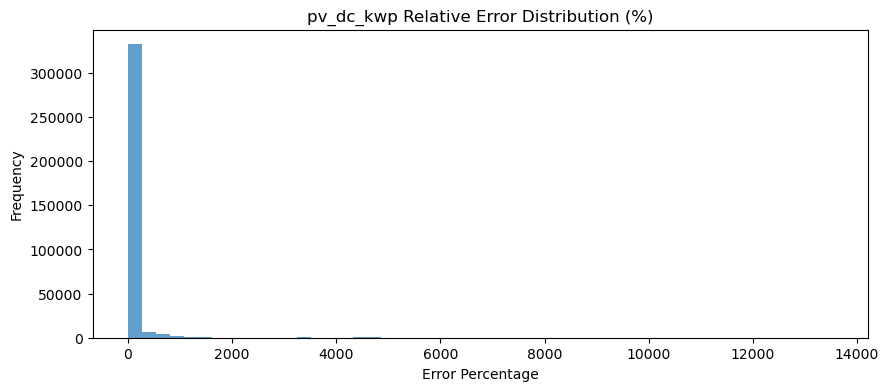

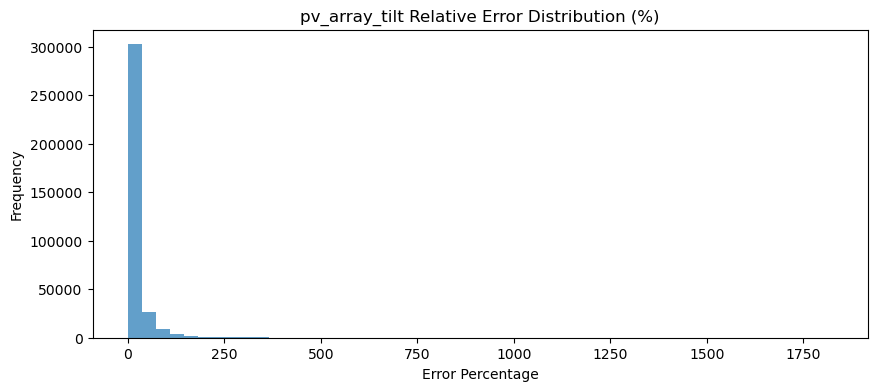

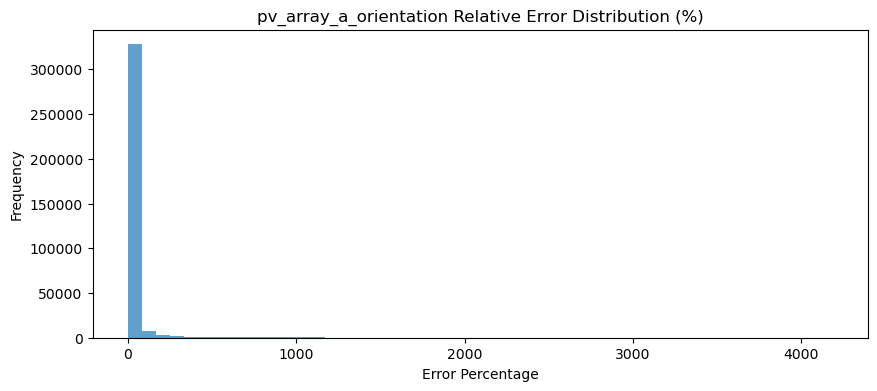

pv_dc_kwp:
  Mean Absolute Error (MAE): 0.06
  Mean Absolute Percentage Error (MAPE): 90.27%
  Maximum Absolute Error: 0.78

pv_array_tilt:
  Mean Absolute Error (MAE): 0.07
  Mean Absolute Percentage Error (MAPE): 27.32%
  Maximum Absolute Error: 0.66

pv_array_a_orientation:
  Mean Absolute Error (MAE): 0.07
  Mean Absolute Percentage Error (MAPE): 43.93%
  Maximum Absolute Error: 0.63



In [52]:
# 确保模型在评估模式
model.eval()

# 预测验证集
with torch.no_grad():
    predictions = model(X_val_tensor)
    
# 反归一化（假设验证数据已归一化）
def inverse_transform(predictions, scaler, feature_indices):
    """
    predictions: 模型输出张量
    scaler: 使用的StandardScaler实例
    feature_indices: 目标特征在原始数据中的列索引
    """
    dummy = np.zeros((len(predictions), len(scaler.mean_)))
    dummy[:, feature_indices] = predictions.cpu().numpy()
    return scaler.inverse_transform(dummy)[:, feature_indices]

# 假设目标特征是最后三列
real_preds = inverse_transform(predictions, scaler, [-3, -2, -1])
real_targets = inverse_transform(y_val_tensor, scaler, [-3, -2, -1])
def calculate_percentage_errors(preds, targets):
    errors = {}
    feature_names = ['pv_dc_kwp', 'pv_array_tilt', 'pv_array_a_orientation']
    
    for i, name in enumerate(feature_names):
        # 绝对误差
        abs_errors = np.abs(preds[:, i] - targets[:, i])
        
        # 相对误差百分比
        relative_errors = abs_errors / (np.abs(targets[:, i]) + 1e-8) * 100
        
        errors[name] = {
            'MAE': np.mean(abs_errors),
            'MAPE': np.mean(relative_errors),
            'MaxError': np.max(abs_errors)
        }
        
        # 绘制误差分布
        plt.figure(figsize=(10,4))
        plt.hist(relative_errors, bins=50, alpha=0.7)
        plt.title(f'{name} Relative Error Distribution (%)')
        plt.xlabel('Error Percentage')
        plt.ylabel('Frequency')
        plt.show()
        
    return errors

# 计算并显示误差
errors = calculate_percentage_errors(real_preds, real_targets)
for name, metrics in errors.items():
    print(f"{name}:")
    print(f"  Mean Absolute Error (MAE): {metrics['MAE']:.2f}")
    print(f"  Mean Absolute Percentage Error (MAPE): {metrics['MAPE']:.2f}%")
    print(f"  Maximum Absolute Error: {metrics['MaxError']:.2f}\n")

## Maybe need to packed each site's data to info NN it's comes from a same site. Time series?


Validation Set Performance Metrics:
pv_dc_kwp:
  MAE: 0.06
  MAPE: 90.27%
pv_array_tilt:
  MAE: 0.07
  MAPE: 27.32%
pv_array_a_orientation:
  MAE: 0.07
  MAPE: 43.93%


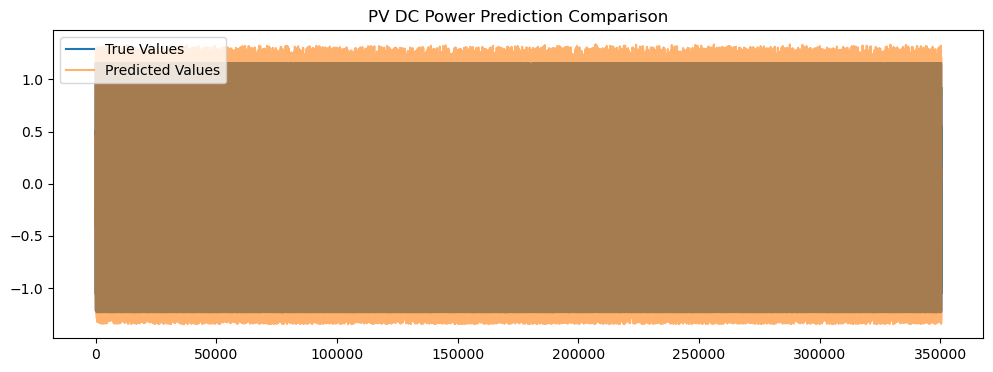

[[ 0.3830857  -1.15177593 -0.52423907]
 [ 1.05989531 -0.10816742  0.03086638]
 [ 1.10761254 -0.34035466 -1.26041727]
 ...
 [-0.3297931  -0.64051156 -0.64514506]
 [ 0.99321776  0.53455438  1.0076139 ]
 [ 0.13946946  1.02555379 -0.6410547 ]]


In [ ]:
# # 加载最佳模型
# model.load_state_dict(torch.load('../models/best_model.pth', map_location=device))

# # 预测
# model.eval()
# with torch.no_grad():
#     predictions = model(X_val_tensor)

# # 反归一化
# def inverse_transform(normalized_data, scaler, feature_indices):
#     """通用反归一化函数"""
#     dummy = np.zeros((len(normalized_data), len(scaler.mean_)))
#     dummy[:, feature_indices] = normalized_data.cpu().numpy() if isinstance(normalized_data, torch.Tensor) else normalized_data
#     return scaler.inverse_transform(dummy)[:, feature_indices]

# # 反归一化预测结果和真实值
# target_indices = [-3, -2, -1]  # 假设目标特征是最后三列
# real_preds = inverse_transform(predictions, scaler, target_indices)
# real_targets = inverse_transform(y_val_tensor, scaler, target_indices) if y_val_tensor is not None else None

# # --------------- 结果验证 ---------------
# if real_targets is not None:
#     # 误差计算
#     def calculate_metrics(preds, targets):
#         errors = {}
#         for i, name in enumerate(['pv_dc_kwp', 'pv_array_tilt', 'pv_array_a_orientation']):
#             abs_errors = np.abs(preds[:,i] - targets[:,i])
#             errors[name] = {
#                 'MAE': np.mean(abs_errors),
#                 'MAPE': np.mean(abs_errors / (np.abs(targets[:,i]) + 1e-8) * 100)
#             }
#         return errors

#     metrics = calculate_metrics(real_preds, real_targets)
    
#     # 打印结果
#     print("\nValidation Set Performance Metrics:")
#     for name, values in metrics.items():
#         print(f"{name}:")
#         print(f"  MAE: {values['MAE']:.2f}")
#         print(f"  MAPE: {values['MAPE']:.2f}%")
    
#     # 可视化（示例：第一个特征的预测对比）
#     plt.figure(figsize=(12,4))
#     plt.plot(real_targets[:,0], label='True Values')
#     plt.plot(real_preds[:,0], alpha=0.6, label='Predicted Values')
#     plt.title("PV DC Power Prediction Comparison")
#     plt.legend()
#     plt.show()
#     print(real_preds)

Rebuild denormalised dataframe to evaluate model

## Neural Network part

In [ ]:
# Julia's version
# Test the model for a random input
input_size = 10
hidden_size = 5
num_classes = 3

batch_size = 4
random_input = torch.randn(batch_size, input_size)

model = SimpleNN(input_size, hidden_size, num_classes)
output = model(random_input)

print("Random Input:")
print(random_input)
print("\nModel Output:")
print(output)


In [ ]:
# def pipeline

In [ ]:
# feature engneering, evaluate importance of each feature
# mutual informations

In [ ]:
# call pipeline, apply suitable validation method, probably K-Fold Cross-Validation？ LOO for extreme small samples